In [7]:
# -*- coding: utf-8 -*-
# 실습 0. 실습용 CSV 파일 만들기
# 교재에서 내려받는 파일 대신 쓸 데이터를 data 폴더에 만든다. 11.4절 실습(lab13~lab16)을 하기 전에 한 번 실행한다.
#  - precipitation.csv      : [표 11-5] 계절별 강수량 (UTF-8)
#  - 학급당학생수.csv        : [그림 11-26] KOSIS 에서 받은 모양 (EUC-KR/CP949, 한글 인코딩)
#  - 지역별면적.csv          : [표 11-6] 지역별 면적 (EUC-KR)
#  - 지역별인구수.csv        : 지역별 인구수 (EUC-KR, 실습용 근사값)
#  - car20240731.csv        : 자동차 연비 데이터를 흉내 낸 실습용 가짜 데이터 (UTF-8, 3498행)
import os
import numpy as np
import pandas as pd

BASE = os.getcwd()
DATA = os.path.join(BASE, 'data')
os.makedirs(DATA, exist_ok=True)

# 1) 강수량 (표 11-5)
prec = pd.DataFrame({'year': [2017, 2018, 2019, 2020, 2021],
                     'spring': [124.9, 383.5, 175.0, 173.7, 330.5],
                     'summer': [612.7, 620.6, 508.2, 1037.6, 612.8],
                     'autumn': [177.9, 351.3, 440.8, 270.4, 256.4],
                     'winter': [75.2, 68.7, 168.8, 47.8, 13.3]})
prec.to_csv(os.path.join(DATA, 'precipitation.csv'), index=False)

# 2) 학급당 학생 수 (그림 11-28 의 값, 한글 인코딩 EUC-KR 계열로 저장)
cls = pd.DataFrame({'항목': ['전체'] * 14,
                    '시점': list(range(2011, 2025)),
                    '서울특별시': [29.36, 28.63, 27.81, 26.96, 26.19, 25.36, 24.60, 23.76,
                                22.96, 22.45, 22.47, 22.03, 21.84, 21.77],
                    '제주특별자치도': [28.88, 28.09, 27.26, 26.46, 25.97, 25.53, 25.25, 24.97,
                                  24.47, 24.15, 23.70, 23.36, 22.72, 22.36]})
cls.to_csv(os.path.join(DATA, '학급당학생수.csv'), index=False, encoding='cp949')

# 3) 지역별 면적(표 11-6, km2)
region = ['서울특별시', '부산광역시', '대구광역시', '인천광역시', '광주광역시', '대전광역시',
          '울산광역시', '세종특별자치시', '경기도', '강원도', '충청북도', '충청남도',
          '전라북도', '전라남도', '경상북도', '경상남도', '제주특별자치도']
area = [605, 770, 884, 1066, 501, 540, 1062, 465, 10197, 16830, 7407, 8247,
        8072, 12359, 19035, 10542, 1850]
pd.DataFrame({'지역': region, '면적': area}).to_csv(
    os.path.join(DATA, '지역별면적.csv'), index=False, encoding='cp949')

# 4) 지역별 인구수 (실습용 근사값)
pop = [9509458, 3350380, 2385412, 2948375, 1441611, 1452251, 1121592, 371895,
       13565450, 1538492, 1597427, 2118183, 1786855, 1832803, 2626609, 3314183, 674635]
pd.DataFrame({'지역': region, '인구수': pop}).to_csv(
    os.path.join(DATA, '지역별인구수.csv'), index=False, encoding='cp949')

# 5) 자동차 연비 데이터 흉내 (난수로 만든 가짜 데이터)
rng = np.random.default_rng(0)
n = 3498
fuel = rng.choice(['휘발유', '경유', '전기'], size=n, p=[0.62, 0.30, 0.08])
disp = np.zeros(n)
co2 = np.full(n, np.nan)
for i, f in enumerate(fuel):
    if f == '휘발유':
        disp[i] = rng.choice([998, 1368, 1598, 1999, 2199, 2497, 2998, 3496, 3998, 4999, 5998])
        co2[i] = np.clip(58 + 0.068 * disp[i] + rng.normal(0, 16), 80, 354)
    elif f == '경유':
        disp[i] = rng.choice([1598, 1995, 2143, 2199, 2993])
        co2[i] = np.clip(88 + 0.045 * disp[i] + rng.normal(0, 22), 90, 260)
cars = pd.DataFrame({
    '업체명': rng.choice(['현대', '기아', '벤츠', '볼보', '토요타', 'BMW'], size=n),
    '모델명': ['모델%04d' % i for i in range(n)],
    '연료': fuel,
    '변속형식': rng.choice(['자동', '수동'], size=n, p=[0.95, 0.05]),
    '차량형식': rng.choice(['세단', 'SUV', '해치백'], size=n),
    '자동차 종류': '승용차',
    '도심주행연비': np.round(rng.uniform(6, 16, n), 1),
    '고속도로연비': np.round(rng.uniform(8, 19, n), 1),
    'CO2배출량(g_km)': np.round(co2),
    '배기량': disp,
    '출시연도': rng.integers(2008, 2025, n)})
# 전기차는 배기량이 0 이다 (교재의 describe 결과에서도 최솟값이 0 이었다)
cars.insert(9, '1회충전주행거리(km)', np.where(fuel == '전기', rng.integers(200, 550, n), np.nan))
cars.to_csv(os.path.join(DATA, 'car20240731.csv'), index=False)

print('만든 파일:')
for f in sorted(os.listdir(DATA)):
    print(' ', f)


만든 파일:
  car20240731.csv
  precipitation.csv
  지역별면적.csv
  지역별인구수.csv
  학급당학생수.csv


In [5]:
# -*- coding: utf-8 -*-
# 실습 1. 데이터프레임 만들기 [코드 11-1 ~ 11-5]
# * 코랩/주피터에서는 display(df) 로 표 모양 출력을 볼 수 있다. 일반 파이썬 파일에서는 print(df) 를 쓴다.
import pandas as pd                          # pd 라는 별칭으로 판다스를 불러온다

# [코드 11-1] 딕셔너리로 만들기: 키 = 열 이름, 값 = 열의 각 행 데이터(리스트)
df = pd.DataFrame({'name': ['Jessica', 'Liam', 'Sophia', 'Ryan', 'Alex'],
                   'test': [45, 30, 40, 37, 48],
                   'assign1': [20, 17, 22, 18, 24],
                   'assign2': [19, 14, 18, 15, 25]})
print(df)                                    # [코드 11-2]
print()

# [코드 11-4] 리스트 + columns 매개변수로 만들기
df2 = pd.DataFrame([['Jessica', 45, 20, 19], ['Liam', 30, 17, 14], ['Sophia', 40, 22, 18],
                    ['Ryan', 37, 18, 15], ['Alex', 48, 24, 25]],
                   columns=['name', 'test', 'assign1', 'assign2'])

# [코드 11-5] 빈 데이터프레임을 만들고 열을 하나씩 추가하기
df3 = pd.DataFrame()
df3['name'] = ['Jessica', 'Liam', 'Sophia', 'Ryan', 'Alex']
df3['test'] = [45, 30, 40, 37, 48]
df3['assign1'] = [20, 17, 22, 18, 24]
df3['assign2'] = [19, 14, 18, 15, 25]

print('세 방법의 결과가 같은가?', df.equals(df2), df.equals(df3))

# 시리즈(1차원)와 데이터프레임(2차원)
s = pd.Series(['Jessica', 'Liam', 'Sophia'])  # 인덱스와 값으로 이루어진 1차원 구조
print(s)
print('shape:', df.shape)                     # (행 수, 열 수)



      name  test  assign1  assign2
0  Jessica    45       20       19
1     Liam    30       17       14
2   Sophia    40       22       18
3     Ryan    37       18       15
4     Alex    48       24       25

세 방법의 결과가 같은가? True True
0    Jessica
1       Liam
2     Sophia
dtype: object
shape: (5, 4)


In [8]:
# -*- coding: utf-8 -*-
# 실습 2. 열 선택, pop, 행 반복 [코드 11-6 ~ 11-9]
import pandas as pd


def make_df():
    return pd.DataFrame({'name': ['Jessica', 'Liam', 'Sophia', 'Ryan', 'Alex'],
                         'test': [45, 30, 40, 37, 48],
                         'assign1': [20, 17, 22, 18, 24],
                         'assign2': [19, 14, 18, 15, 25]})


df = make_df()

print('-- [코드 11-6] 열 하나 선택 --')
print(df['name'])                            # 한 열을 고르면 시리즈가 된다

print('-- [코드 11-7] 열 여러 개 선택 --')
print(df[['name', 'test']])                  # 열 이름을 리스트로 묶으면 데이터프레임이 된다

print('-- [코드 11-8] pop: 열을 꺼내고 삭제 --')
n = df.pop('name')                           # name 열을 n 에 담고 df 에서는 지운다
print(list(n))
print(list(df.columns))

print('-- [코드 11-9] iterrows: 행마다 반복 --')
df = make_df()                               # name 열이 있는 원래 데이터프레임으로 다시 시작
for index, row in df.iterrows():             # index: 행 인덱스, row: 그 행의 데이터
    print(index, row['name'], row['test'])


-- [코드 11-6] 열 하나 선택 --
0    Jessica
1       Liam
2     Sophia
3       Ryan
4       Alex
Name: name, dtype: object
-- [코드 11-7] 열 여러 개 선택 --
      name  test
0  Jessica    45
1     Liam    30
2   Sophia    40
3     Ryan    37
4     Alex    48
-- [코드 11-8] pop: 열을 꺼내고 삭제 --
['Jessica', 'Liam', 'Sophia', 'Ryan', 'Alex']
['test', 'assign1', 'assign2']
-- [코드 11-9] iterrows: 행마다 반복 --
0 Jessica 45
1 Liam 30
2 Sophia 40
3 Ryan 37
4 Alex 48


In [9]:
# 실습 3. 열 추가와 조건에 맞는 행 추출 [코드 11-10 ~ 11-12]
import pandas as pd

df = pd.DataFrame({'name': ['Jessica', 'Liam', 'Sophia', 'Ryan', 'Alex'],
                   'test': [45, 30, 40, 37, 48],
                   'assign1': [20, 17, 22, 18, 24],
                   'assign2': [19, 14, 18, 15, 25]})

# [코드 11-10] 열끼리 계산해서 새 열 추가 (반복문 없이 한 번에 계산된다)
df['sum'] = df['test'] + df['assign1'] + df['assign2']
print(df)

# [코드 11-11] 조건에 맞는 행만 추출: df[조건]
print(df[df['sum'] >= 80])

# [코드 11-12] 조건에 맞는 행의 특정 열만 추출: df[조건][열 리스트]
print(df[df['sum'] >= 80][['name', 'sum']])


      name  test  assign1  assign2  sum
0  Jessica    45       20       19   84
1     Liam    30       17       14   61
2   Sophia    40       22       18   80
3     Ryan    37       18       15   70
4     Alex    48       24       25   97
      name  test  assign1  assign2  sum
0  Jessica    45       20       19   84
2   Sophia    40       22       18   80
4     Alex    48       24       25   97
      name  sum
0  Jessica   84
2   Sophia   80
4     Alex   97


In [10]:
# -*- coding: utf-8 -*-
# 실습 4. rename, sort_values [코드 11-13, 11-14]
import pandas as pd

df = pd.DataFrame({'name': ['Jessica', 'Liam', 'Sophia', 'Ryan', 'Alex'],
                   'test': [45, 30, 40, 37, 48],
                   'assign1': [20, 17, 22, 18, 24],
                   'assign2': [19, 14, 18, 15, 25]})
df['sum'] = df['test'] + df['assign1'] + df['assign2']

# [코드 11-13] 열 이름 변경. inplace=True 면 df 자체가 바뀐다
df.rename(columns={'test': 'exam'}, inplace=True)
print(df)

# [코드 11-14] 'sum' 열 기준 내림차순 정렬 (기본은 오름차순)
sort_df = df.sort_values('sum', ascending=False)
print(sort_df)
print('원래 df 의 순서는 그대로:', list(df['name']))   # sort_values 는 새 데이터프레임을 돌려준다



      name  exam  assign1  assign2  sum
0  Jessica    45       20       19   84
1     Liam    30       17       14   61
2   Sophia    40       22       18   80
3     Ryan    37       18       15   70
4     Alex    48       24       25   97
      name  exam  assign1  assign2  sum
4     Alex    48       24       25   97
0  Jessica    45       20       19   84
2   Sophia    40       22       18   80
3     Ryan    37       18       15   70
1     Liam    30       17       14   61
원래 df 의 순서는 그대로: ['Jessica', 'Liam', 'Sophia', 'Ryan', 'Alex']


In [11]:
# -*- coding: utf-8 -*-
# 실습 5. np.where 로 등급 매기기, value_counts [코드 11-15 ~ 11-18]
import numpy as np
import pandas as pd

df = pd.DataFrame({'name': ['Jessica', 'Liam', 'Sophia', 'Ryan', 'Alex'],
                   'exam': [45, 30, 40, 37, 48],
                   'assign1': [20, 17, 22, 18, 24],
                   'assign2': [19, 14, 18, 15, 25]})
df['sum'] = df['exam'] + df['assign1'] + df['assign2']

# [코드 11-15] 90 이상 A, 80 이상 B, 나머지 C  (np.where 를 겹쳐 쓴다, CH09 참고)
df['grade'] = np.where(df['sum'] >= 90, 'A',
                       np.where(df['sum'] >= 80, 'B', 'C'))

# [코드 11-16] 80 이상 pass, 미만 fail
df['result'] = np.where(df['sum'] >= 80, 'pass', 'fail')
print(df)

print(df['result'].value_counts())           # [코드 11-17] 값의 빈도수 (많은 순)
print(df['grade'].value_counts())            # [코드 11-18]

df.drop(columns='result', inplace=True)      # [코드 11-19] 열 삭제
print(list(df.columns))


      name  exam  assign1  assign2  sum grade result
0  Jessica    45       20       19   84     B   pass
1     Liam    30       17       14   61     C   fail
2   Sophia    40       22       18   80     B   pass
3     Ryan    37       18       15   70     C   fail
4     Alex    48       24       25   97     A   pass
result
pass    3
fail    2
Name: count, dtype: int64
grade
B    2
C    2
A    1
Name: count, dtype: int64
['name', 'exam', 'assign1', 'assign2', 'sum', 'grade']


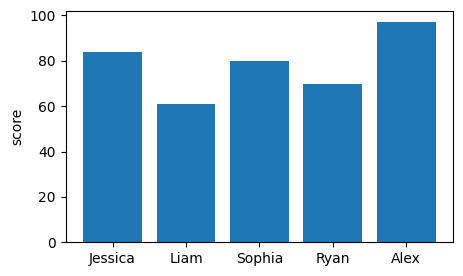

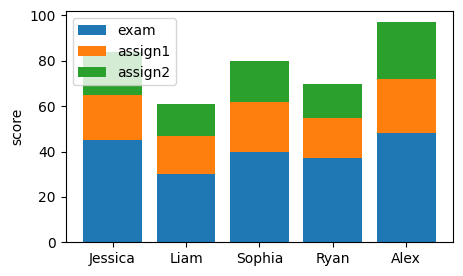

In [12]:
# -*- coding: utf-8 -*-
# 실습 6. 데이터프레임으로 그래프 그리기 [코드 11-20, 11-21]
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({'name': ['Jessica', 'Liam', 'Sophia', 'Ryan', 'Alex'],
                   'exam': [45, 30, 40, 37, 48],
                   'assign1': [20, 17, 22, 18, 24],
                   'assign2': [19, 14, 18, 15, 25]})
df['sum'] = df['exam'] + df['assign1'] + df['assign2']

# [코드 11-20] 열(시리즈)을 그대로 bar 의 x, y 로 쓴다
plt.figure(figsize=(5, 3))
plt.bar(df['name'], df['sum'])
plt.ylabel('score')
plt.show()

# [코드 11-21] 누적 막대 그래프: bottom 에 아래 막대의 높이를 넘긴다 (열끼리 더한 결과)
plt.figure(figsize=(5, 3))
plt.bar(df['name'], df['exam'], label='exam')
plt.bar(df['name'], df['assign1'], bottom=df['exam'], label='assign1')
plt.bar(df['name'], df['assign2'], bottom=df['exam'] + df['assign1'], label='assign2')
plt.legend()
plt.ylabel('score')
plt.show()


In [13]:
# -*- coding: utf-8 -*-
# 실습 7. 누락 데이터(NaN) 찾기와 삭제 [코드 11-22 ~ 11-27]
import numpy as np
import pandas as pd

df = pd.DataFrame({'name': ['Jessica', 'Liam', 'Sophia', 'Ryan', 'Alex'],
                   'gender': ['F', np.nan, np.nan, 'M', 'F'],       # np.nan: 누락된 값
                   'score': [89, 75, 95, np.nan, 93]})
print(df)                                    # [코드 11-22] 누락 값은 NaN 으로 보인다

print(pd.isna(df))                           # [코드 11-23] 누락이면 True
print(pd.isna(df).sum())                     # [코드 11-24] 열마다 누락 개수 (True 는 1 로 계산)

clean = df.dropna()                          # [코드 11-25] 누락이 있는 행을 모두 삭제
print(clean)

clean = df.dropna(subset=['name', 'score'])  # [코드 11-26] name, score 가 누락된 행만 삭제
print(clean)

df.dropna(subset=['name', 'score'], inplace=True)   # [코드 11-27] inplace=True: df 자체에 반영
print(df)


      name gender  score
0  Jessica      F   89.0
1     Liam    NaN   75.0
2   Sophia    NaN   95.0
3     Ryan      M    NaN
4     Alex      F   93.0
    name  gender  score
0  False   False  False
1  False    True  False
2  False    True  False
3  False   False   True
4  False   False  False
name      0
gender    2
score     1
dtype: int64
      name gender  score
0  Jessica      F   89.0
4     Alex      F   93.0
      name gender  score
0  Jessica      F   89.0
1     Liam    NaN   75.0
2   Sophia    NaN   95.0
4     Alex      F   93.0
      name gender  score
0  Jessica      F   89.0
1     Liam    NaN   75.0
2   Sophia    NaN   95.0
4     Alex      F   93.0


In [14]:
# -*- coding: utf-8 -*-
# 실습 8. fillna 로 누락 데이터 채우기 [코드 11-28 ~ 11-31]
import numpy as np                           # 교재 코드 11-28 에는 이 줄이 빠져 있다 (np.nan 을 쓰려면 필요)
import pandas as pd

df = pd.DataFrame({'name': ['Jessica', 'Liam', 'Sophia', 'Ryan', 'Alex'],
                   'gender': ['F', np.nan, np.nan, 'M', 'F'],
                   'score': [89, 75, 95, np.nan, 93]})

df1 = df.fillna(0)                           # [코드 11-28] 모든 누락을 0 으로
print(df1)

df1 = df.fillna({'gender': 'etc', 'score': 0})          # [코드 11-29] 열마다 다른 값으로
print(df1)

mean = df['score'].mean()                    # 누락(NaN)은 빼고 평균을 구한다
print('score 평균:', mean)
df1 = df.fillna({'gender': 'etc', 'score': mean})       # [코드 11-30] 평균으로 채우기
print(df1)

df.fillna({'gender': 'etc', 'score': df['score'].mean()}, inplace=True)   # [코드 11-31]
print(df)


      name gender  score
0  Jessica      F   89.0
1     Liam      0   75.0
2   Sophia      0   95.0
3     Ryan      M    0.0
4     Alex      F   93.0
      name gender  score
0  Jessica      F   89.0
1     Liam    etc   75.0
2   Sophia    etc   95.0
3     Ryan      M    0.0
4     Alex      F   93.0
score 평균: 88.0
      name gender  score
0  Jessica      F   89.0
1     Liam    etc   75.0
2   Sophia    etc   95.0
3     Ryan      M   88.0
4     Alex      F   93.0
      name gender  score
0  Jessica      F   89.0
1     Liam    etc   75.0
2   Sophia    etc   95.0
3     Ryan      M   88.0
4     Alex      F   93.0


In [15]:
# -*- coding: utf-8 -*-
# 실습 9. merge 로 데이터프레임 합치기 [코드 11-32 ~ 11-36]
import pandas as pd

# [코드 11-32] (교재 3행의 'Ryan',,'Alex' 는 쉼표가 두 개라 오류이므로 하나로 쓴다)
df1 = pd.DataFrame({'name': ['Jessica', 'Liam', 'Sophia', 'Ryan', 'Alex'],
                    'gender': ['F', 'M', 'F', 'M', 'F'],
                    'age': [21, 23, 20, 22, 20]})
df2 = pd.DataFrame({'name': ['Sophia', 'Liam', 'Ryan', 'Alex', 'Jessica'],      # 순서가 df1 과 다르다
                    'department': ['computer science', 'mathematics', 'law',
                                   'computer science', 'law']})

df3 = pd.merge(df1, df2)                     # [코드 11-33] 이름이 같은 열(name)을 기준으로 결합
print(df3)

df3 = pd.merge(df1, df2, on='name')          # [코드 11-34] 기준 열을 on 으로 직접 지정 (권장)
print(df3)

# [코드 11-35] 학과별 학과장 정보
df4 = pd.DataFrame({'department': ['computer science', 'mathematics', 'law'],
                    'head of department': ['Steve', 'Emma', 'Carly']})
df5 = pd.merge(df3, df4, on='department')    # [코드 11-36] department 기준으로 또 결합
print(df5)


      name gender  age        department
0  Jessica      F   21               law
1     Liam      M   23       mathematics
2   Sophia      F   20  computer science
3     Ryan      M   22               law
4     Alex      F   20  computer science
      name gender  age        department
0  Jessica      F   21               law
1     Liam      M   23       mathematics
2   Sophia      F   20  computer science
3     Ryan      M   22               law
4     Alex      F   20  computer science
      name gender  age        department head of department
0  Jessica      F   21               law              Carly
1     Ryan      M   22               law              Carly
2     Liam      M   23       mathematics               Emma
3   Sophia      F   20  computer science              Steve
4     Alex      F   20  computer science              Steve


In [16]:
# -*- coding: utf-8 -*-
# 실습 10. 판다스 통계 함수 [표 11-1, 코드 11-37]
import pandas as pd

df = pd.DataFrame({'test': [45, 30, 40, 37, 48]})
print('count()  개수\n', df.count())
print('sum()    합\n', df.sum())
print('cumsum() 누적 합\n', df.cumsum())
print('mean()   평균\n', df.mean())
print('std()    표준편차\n', df.std())
print('var()    분산\n', df.var())
print('max()    최댓값\n', df.max())
print('min()    최솟값\n', df.min())

# [코드 11-37] 여러 열에 describe(): 열마다 기초 통계량을 한꺼번에 구한다
df = pd.DataFrame({'test': [45, 30, 40, 37, 48],
                   'assign1': [20, 17, 22, 18, 24],
                   'assign2': [19, 14, 18, 15, 25]})
print(df.describe())


count()  개수
 test    5
dtype: int64
sum()    합
 test    200
dtype: int64
cumsum() 누적 합
    test
0    45
1    75
2   115
3   152
4   200
mean()   평균
 test    40.0
dtype: float64
std()    표준편차
 test    7.035624
dtype: float64
var()    분산
 test    49.5
dtype: float64
max()    최댓값
 test    48
dtype: int64
min()    최솟값
 test    30
dtype: int64
            test    assign1   assign2
count   5.000000   5.000000   5.00000
mean   40.000000  20.200000  18.20000
std     7.035624   2.863564   4.32435
min    30.000000  17.000000  14.00000
25%    37.000000  18.000000  15.00000
50%    40.000000  20.000000  18.00000
75%    45.000000  22.000000  19.00000
max    48.000000  24.000000  25.00000


In [17]:
# -*- coding: utf-8 -*-
# 실습 11. 판다스 문자열 함수와 자료형 변환 [표 11-2, 11-3, 코드 11-38]
import pandas as pd

df = pd.DataFrame({'높이': ['1,250미터', '740', '높이1,130미터']})
print(df['높이'].str.find('미터'))            # find: 문자열 위치(없으면 -1)
print(df['높이'].str.strip().str.rstrip('미터'))     # rstrip: 오른쪽의 '미', '터' 글자들을 제거
print(df['높이'].str.strip().str.lstrip('높이'))     # lstrip: 왼쪽의 '높', '이' 글자들을 제거
print(df['높이'].str.replace(',', ''))        # replace: 문자열 교체

# [표 11-3] astype: 자료형 변환 (문자열 -> 정수)
df2 = pd.DataFrame({'높이': ['1250', '740', '1130']})
df2['높이'] = df2['높이'].astype(int)
print(df2['높이'] + 1)                         # 정수가 되었으므로 계산이 된다

# [코드 11-38] 함수를 이어 붙여(체이닝) 한 번에 정리하기
df = pd.DataFrame({'온도': ['섭씨10도', '20', '15도'],
                   '높이': ['1,250미터', '740', '1,130미터']})
df['온도'] = df['온도'].str.strip() \
                     .str.rstrip('도') \
                     .str.lstrip('섭씨') \
                     .astype(int)
df['높이'] = df['높이'].str.strip() \
                     .str.rstrip('미터') \
                     .str.replace(',', '') \
                     .astype(int)
print(df)
print(df.dtypes)


0    5
1   -1
2    7
Name: 높이, dtype: int64
0      1,250
1        740
2    높이1,130
Name: 높이, dtype: object
0    1,250미터
1        740
2    1,130미터
Name: 높이, dtype: object
0      1250미터
1         740
2    높이1130미터
Name: 높이, dtype: object
0    1251
1     741
2    1131
Name: 높이, dtype: int64
   온도    높이
0  10  1250
1  20   740
2  15  1130
온도    int64
높이    int64
dtype: object


   nation  gold  silver  bronze
0   Korea    12      10      11
1     USA    36      31      27
2   Japan     4       3       7
3  France     6       4       6
   nation  total
0   Korea     33
1     USA     94
2   Japan     14
3  France     16


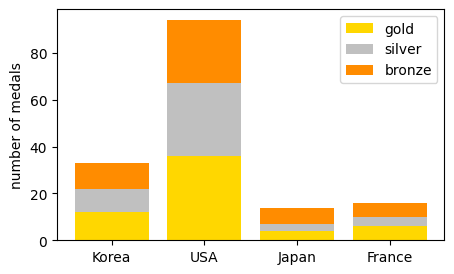

In [18]:
# -*- coding: utf-8 -*-
# 실습 12. 1988 서울 올림픽 메달 수 누적 막대 그래프 [표 11-4, 코드 11-39]
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({'nation': ['Korea', 'USA', 'Japan', 'France'],
                   'gold': [12, 36, 4, 6],
                   'silver': [10, 31, 3, 4],
                   'bronze': [11, 27, 7, 6]})
print(df)

df['total'] = df['gold'] + df['silver'] + df['bronze']
print(df[['nation', 'total']])

plt.figure(figsize=(5, 3))
plt.bar(df['nation'], df['gold'], color='gold', label='gold')
plt.bar(df['nation'], df['silver'], color='silver', bottom=df['gold'], label='silver')
plt.bar(df['nation'], df['bronze'], color='darkorange',
        bottom=df['gold'] + df['silver'], label='bronze')
plt.legend()
plt.ylabel('number of medals')
plt.show()


   nation  gold  silver  bronze
0   Korea    12      10      11
1     USA    36      31      27
2   Japan     4       3       7
3  France     6       4       6
   nation  total
0   Korea     33
1     USA     94
2   Japan     14
3  France     16


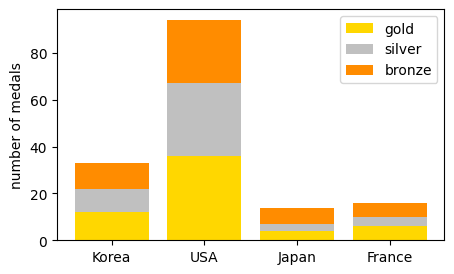

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({'nation': ['Korea', 'USA', 'Japan', 'France'],
                   'gold': [12, 36, 4, 6],
                   'silver': [10, 31, 3, 4],
                   'bronze': [11, 27, 7, 6]})
print(df)

df['total'] = df['gold'] + df['silver'] + df['bronze']
print(df[['nation', 'total']])

plt.figure(figsize=(5, 3))
plt.bar(df['nation'], df['gold'], color='gold', label='gold')
plt.bar(df['nation'], df['silver'], color='silver', bottom=df['gold'], label='silver')
plt.bar(df['nation'], df['bronze'], color='darkorange',
        bottom=df['gold'] + df['silver'], label='bronze')
plt.legend()
plt.ylabel('number of medals')
plt.show()

In [20]:
# 먼저 lab00_make_data.py 를 한 번 실행해 data 폴더를 만든다.
import os
import pandas as pd
import matplotlib.pyplot as plt

os.chdir(os.path.join(os.path.dirname(os.path.abspath(__file__)), 'data'))   # data 폴더로 이동

df = pd.read_csv('precipitation.csv')        # [코드 11-40] CSV 파일 -> 데이터프레임
print(df)

plt.figure(figsize=(6, 4))                   # [코드 11-41] 누적 막대 그래프 (CH09 코드 9-15 와 같은 모양)
plt.bar(df['year'], df['spring'], label='spring')
plt.bar(df['year'], df['summer'], bottom=df['spring'], label='summer')
plt.bar(df['year'], df['autumn'], bottom=(df['spring'] + df['summer']), label='autumn')
plt.bar(df['year'], df['winter'], bottom=(df['spring'] + df['summer'] + df['autumn']),
        label='winter')
plt.ylabel('precipitation')
plt.xlabel('year')
plt.legend()
plt.show()

df['sum'] = df['spring'] + df['summer'] + df['autumn'] + df['winter']   # [코드 11-42]
print(df)

df.to_csv('precipitation_out.csv')           # [코드 11-43] 행 인덱스 0~4 도 같이 저장된다
print(pd.read_csv('precipitation_out.csv').columns.tolist())   # 첫 열 'Unnamed: 0' 이 생긴다

df.to_csv('precipitation_out.csv', index=False)   # [코드 11-44] index=False: 행 인덱스는 저장하지 않는다
print(pd.read_csv('precipitation_out.csv').columns.tolist())

NameError: name '__file__' is not defined

In [21]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.chdir(os.path.join(os.path.dirname(os.path.abspath(__file__)), 'data'))

try:                                          # [코드 11-45] 인코딩을 지정하지 않으면?
    df = pd.read_csv('학급당학생수.csv')
except UnicodeDecodeError:
    print('UnicodeDecodeError: 이 파일은 utf-8 이 아니라서 읽을 수 없다')

df = pd.read_csv('학급당학생수.csv', encoding='EUC-KR')   # [코드 11-46] 한글 인코딩을 EUC-KR 로 지정
print(df)

print(df.head())                              # [코드 11-47] 앞 5행
print(df.tail())                              # 뒤 5행
print(df.shape)                               # [코드 11-48] (행 수, 열 수)

# 한글이 보이도록 글꼴 설정 (코랩에서는 [코드 11-49, 11-50] 처럼 나눔 글꼴을 설치해 쓴다)
import platform
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')       # 윈도우 한글 글꼴
elif platform.system() == 'Darwin':
    plt.rc('font', family='AppleGothic')         # 맥 한글 글꼴
else:
    plt.rc('font', family='NanumGothic')         # 코랩: [코드 11-49]로 나눔 글꼴을 먼저 설치
plt.rcParams['axes.unicode_minus'] = False       # 음수 부호(-)가 깨지지 않게

ind = np.arange(len(df))                      # [코드 11-51]
plt.figure(figsize=(5, 3))
plt.plot(ind, df['서울특별시'], label='seoul')
plt.plot(ind, df['제주특별자치도'], label='jeju')
plt.xticks(ind, df['시점'])                    # 눈금 위치와 눈금 이름 (CH09)
plt.ylim(15, 30)
plt.legend()
plt.xlabel('연도')
plt.ylabel('학급당 학생 수')
plt.xticks(rotation='vertical')               # 눈금 글자를 세로로 눕힌다
plt.show()

NameError: name '__file__' is not defined

In [22]:
# 교재 코드 11-52 의 14~21행은 슬라이드에 없어서, 같은 흐름(결합 -> 인구밀도 계산 -> 막대 그래프)으로 채운 것이다.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.chdir(os.path.join(os.path.dirname(os.path.abspath(__file__)), 'data'))
import platform
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')       # 윈도우 한글 글꼴
elif platform.system() == 'Darwin':
    plt.rc('font', family='AppleGothic')         # 맥 한글 글꼴
else:
    plt.rc('font', family='NanumGothic')         # 코랩: [코드 11-49]로 나눔 글꼴을 먼저 설치
plt.rcParams['axes.unicode_minus'] = False       # 음수 부호(-)가 깨지지 않게

df1 = pd.read_csv('지역별면적.csv', encoding='EUC-KR')
df2 = pd.read_csv('지역별인구수.csv', encoding='EUC-KR')
print(df1.head(3))
print(df2.head(3))

df = pd.merge(df1, df2, on='지역')            # 지역 이름을 기준으로 결합
df['인구밀도'] = df['인구수'] / df['면적']      # 인구밀도 = 인구수 / 면적 (명/km2)
df = df.sort_values('인구밀도', ascending=False)
print(df[['지역', '인구밀도']].head(5).round(1))

ind = np.arange(len(df))
plt.figure(figsize=(6, 3.5))
plt.bar(ind, df['인구밀도'])
plt.xlabel('지역')
plt.ylabel('인구밀도')
plt.xticks(ind, df['지역'], rotation='vertical', fontsize=9)
plt.show()

NameError: name '__file__' is not defined